In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_abnormal.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_normal.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_test.csv
/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
abnormal = pd.read_csv("/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_abnormal.csv")

In [4]:
abnormal

,9.322328567504882812e-01,8.696785569190979004e-01,8.861859440803527832e-01,9.296264052391052246e-01,9.087749719619750977e-01,9.339704513549804688e-01,8.010425567626953125e-01,7.497828006744384766e-01,6.872285008430480957e-01,6.350998878479003906e-01,...,0.000000000000000000e+00.117,0.000000000000000000e+00.118,0.000000000000000000e+00.119,0.000000000000000000e+00.120,0.000000000000000000e+00.121,0.000000000000000000e+00.122,0.000000000000000000e+00.123,0.000000000000000000e+00.124,0.000000000000000000e+00.125,1.000000000000000000e+00.1
0,1.000000,0.606941,0.384181,0.254237,0.223567,0.276836,0.253430,0.184826,0.153349,0.121872,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.000000,0.951613,0.923963,0.853303,0.791859,0.734255,0.672043,0.685100,0.670507,0.667435,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.977819,0.899261,0.230129,0.032348,0.142329,0.223660,0.328096,0.367837,0.381701,0.389094,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.935618,0.801661,0.805815,1.000000,0.722741,0.480789,0.454829,0.319834,0.266874,0.308411,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.925265,0.433352,0.073620,0.079197,0.136643,0.182934,0.182934,0.182376,0.196877,0.203569,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10500,0.981409,1.000000,0.559171,0.287093,0.196639,0.204862,0.215946,0.243833,0.242760,0.250268,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10501,0.906250,0.922379,0.878024,0.810484,0.712702,0.667339,0.608871,0.527218,0.480847,0.442540,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10502,1.000000,0.867971,0.674122,0.470332,0.296987,0.169307,0.077664,0.081392,0.074868,0.089779,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
10503,1.000000,0.984672,0.658888,0.556394,0.446809,0.395790,0.315260,0.276367,0.261039,0.258522,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### each individual row represents a single complete ECG heartbeat signal, and the columns represent the sequential discrete data points (amplitudes) over time. The last column is usually the categorical class label (e.g., normal vs. abnormal).

In [5]:
# Assuming the last column is the class label, we drop it to isolate the signal
signals = abnormal.iloc[:, :-1] 
labels = abnormal.iloc[:, -1]

In [6]:
# 3. Select a specific heartbeat row to visualize (e.g., the first row)
row_index = 0
heartbeat_signal = signals.iloc[row_index]
heartbeat_label = labels.iloc[row_index]

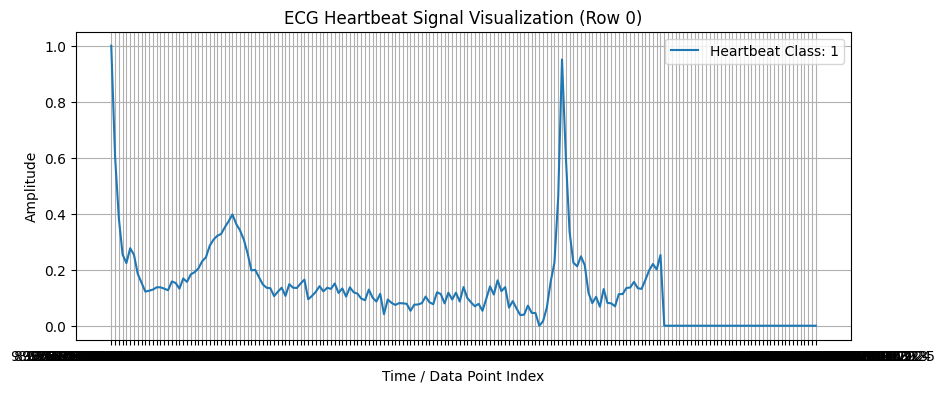

In [7]:
# 4. Plot the discrete points as a continuous line graph
plt.figure(figsize=(10, 4))
plt.plot(heartbeat_signal, label=f"Heartbeat Class: {int(heartbeat_label)}")

plt.title(f"ECG Heartbeat Signal Visualization (Row {row_index})")
plt.xlabel("Time / Data Point Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
normal = pd.read_csv("/kaggle/input/datasets/shayanfazeli/heartbeat/ptbdb_normal.csv")

In [9]:
normal.head(5)

,1.000000000000000000e+00,9.003241658210754395e-01,3.585899472236633301e-01,5.145867168903350830e-02,4.659643396735191345e-02,1.268233358860015869e-01,1.333063244819641113e-01,1.191247999668121338e-01,1.106158867478370667e-01,1.130470037460327148e-01,...,0.000000000000000000e+00.56,0.000000000000000000e+00.57,0.000000000000000000e+00.58,0.000000000000000000e+00.59,0.000000000000000000e+00.60,0.000000000000000000e+00.61,0.000000000000000000e+00.62,0.000000000000000000e+00.63,0.000000000000000000e+00.64,0.000000000000000000e+00.65
0,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.948983,0.505265,0.004176,0.022513,0.059550,0.107298,0.110385,0.111293,0.116558,0.118192,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [10]:
normal.shape

(4045, 188)

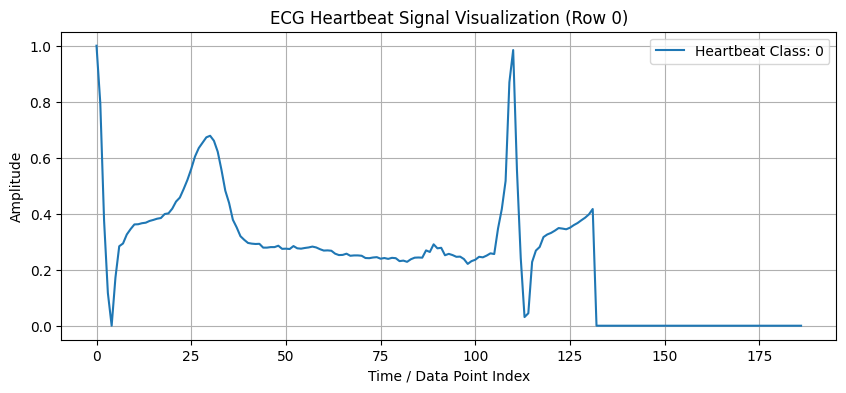

In [11]:
signal = normal.iloc[:,:-1]
label = normal.iloc[:,-1]

row_index = 0
heartbeat_signal = signal.iloc[row_index]
heartbeat_label = label.iloc[row_index]

plt.figure(figsize=(10, 4))
# Change this line in your code:
plt.plot(heartbeat_signal.values, label=f"Heartbeat Class: {int(heartbeat_label)}")

plt.title(f"ECG Heartbeat Signal Visualization (Row {row_index})")
plt.xlabel("Time / Data Point Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

## Let's start work

In [12]:
df = pd.read_csv("/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_train.csv")

In [13]:
# 2. Separate features (signals) and labels
# We assume the very last column holds the class numbers (0, 1, 2, 3, or 4)
signals = df.iloc[:, :-1]
labels = df.iloc[:, -1]

In [14]:
# 3. Define human-readable labels for our plot legend
class_names = {
    0: "Normal Beat",
    1: "Supraventricular",
    2: "Ventricular",
    3: "Fusion Beat",
    4: "Unknown Beat"
}

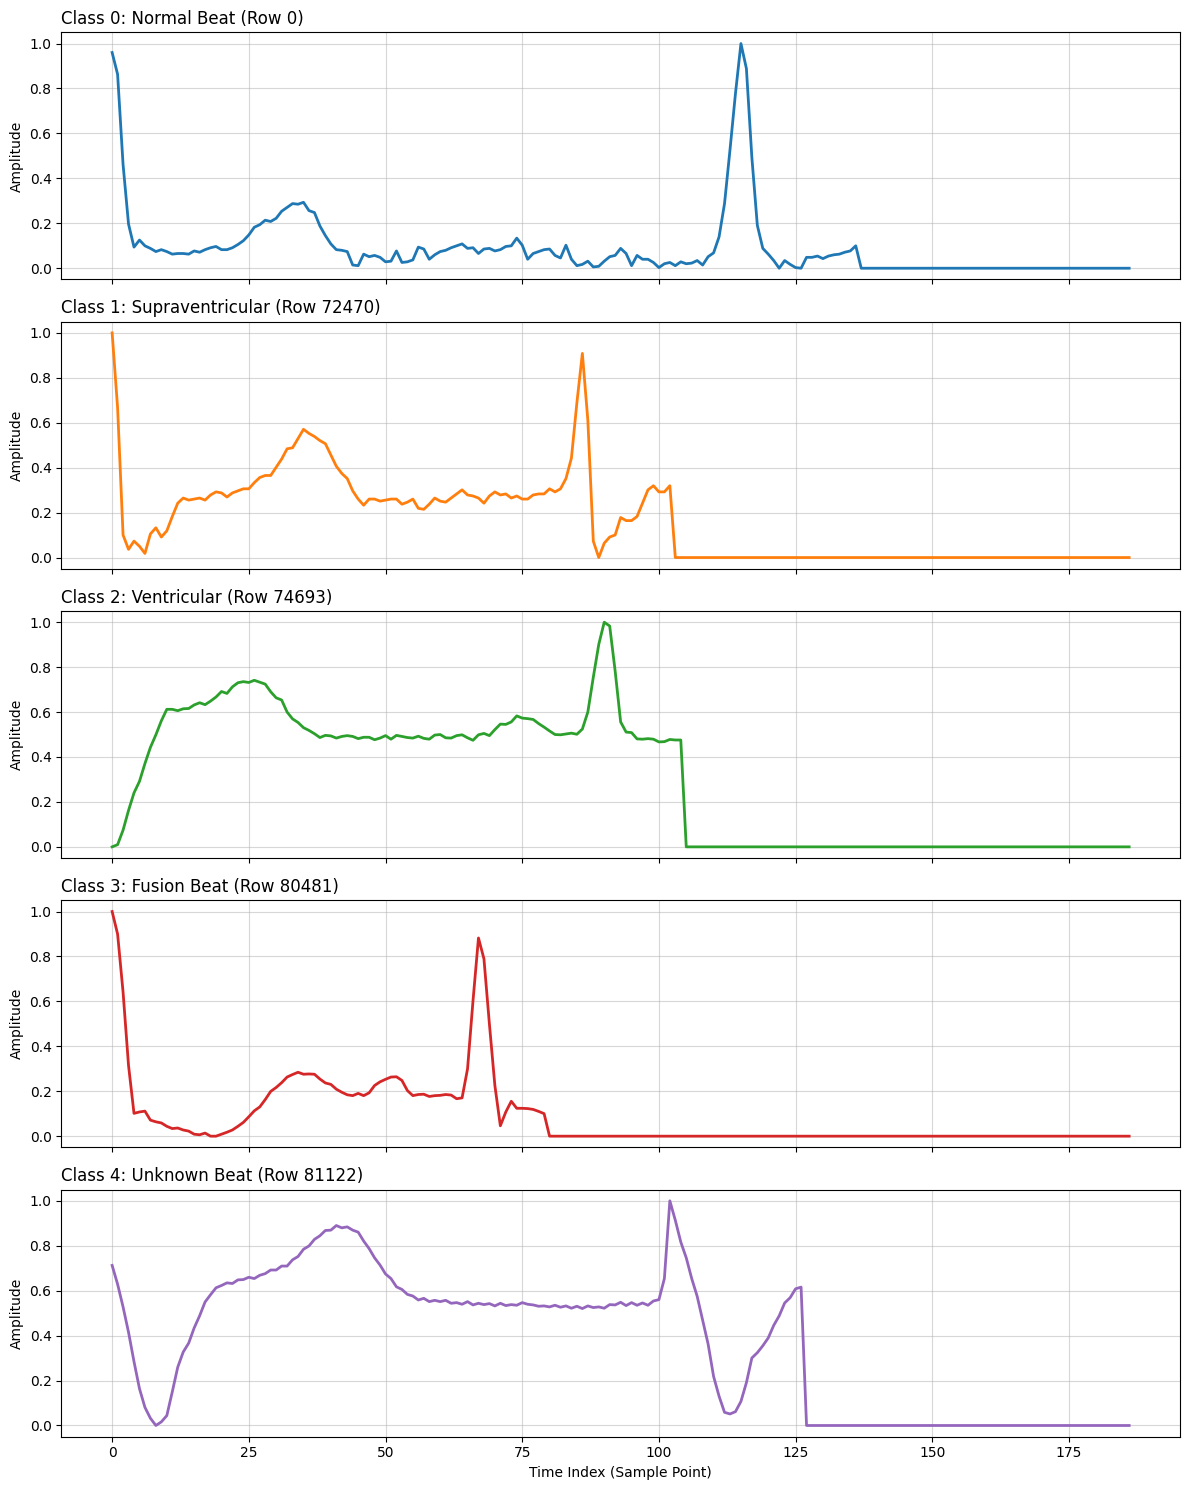

In [15]:
# 4. Create a multi-plot layout (5 rows, 1 column)
fig, axes = plt.subplots(5, 1, figsize=(12, 15), sharex=True)

# 5. Loop through each class, find the first occurrence, and plot it
for target_class in range(5):
    # Find the index of the first row belonging to this class
    class_indices = labels[labels == target_class].index
    
    if len(class_indices) > 0:
        first_row_idx = class_indices[0]
        
        # Extract the signal and drop the string index (.values forces numeric x-axis)
        single_heartbeat = signals.iloc[first_row_idx].values
        
        # Plot onto the specific subplot axis
        ax = axes[target_class]
        ax.plot(single_heartbeat, color=f"C{target_class}", linewidth=2)
        
        # Add visual context
        ax.set_title(f"Class {target_class}: {class_names[target_class]} (Row {first_row_idx})", fontsize=12, loc='left')
        ax.grid(True, alpha=0.5)
        ax.set_ylabel("Amplitude")
    else:
        axes[target_class].set_title(f"Class {target_class}: No samples found in this file.")

# Global styling adjustments
plt.xlabel("Time Index (Sample Point)")
plt.tight_layout()
plt.show()

In [16]:
# Count how many rows exist for each individual class
# .value_counts() groups the identical labels together and counts them
class_counts = labels.value_counts().sort_index()
class_counts

0.000000000000000000e+00.88
0.0    72470
1.0     2223
2.0     5788
3.0      641
4.0     6431
Name: count, dtype: int64

## Checking if there is class imbalance or not

In [17]:
# 5. Calculate percentages to see the scale of the imbalance
total_samples = len(labels)
print("--- DATASET DISTRIBUTION ---")
for class_id, count in class_counts.items():
    percentage = (count / total_samples) * 100
    print(f"Class {class_id} ({class_names[class_id]}): {count} rows ({percentage:.2f}%)")

--- DATASET DISTRIBUTION ---
Class 0.0 (Normal Beat): 72470 rows (82.77%)
Class 1.0 (Supraventricular): 2223 rows (2.54%)
Class 2.0 (Ventricular): 5788 rows (6.61%)
Class 3.0 (Fusion Beat): 641 rows (0.73%)
Class 4.0 (Unknown Beat): 6431 rows (7.35%)


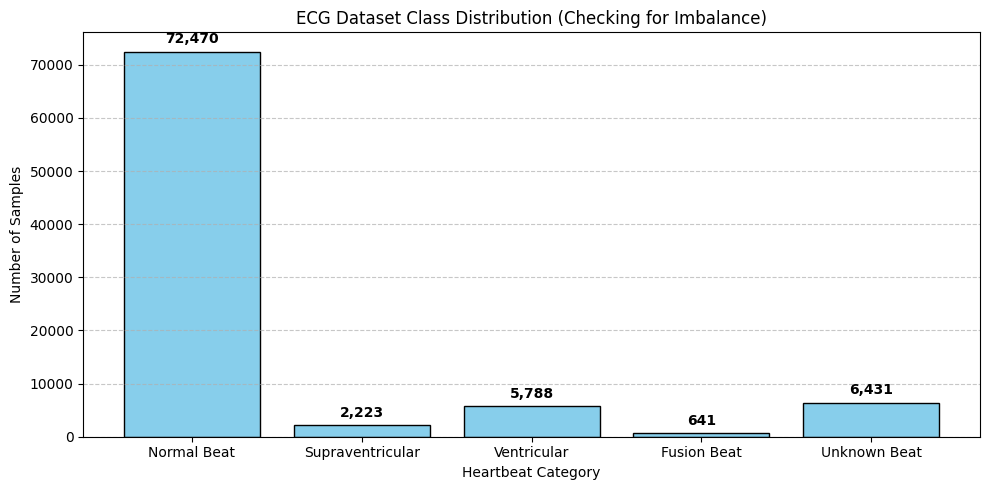

In [18]:
# 6. Plot the distribution as a Bar Chart
plt.figure(figsize=(10, 5))
bars = plt.bar([class_names[i] for i in class_counts.index], class_counts.values, color='skyblue', edgecolor='black')

# Add the raw counts on top of each bar for readability
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f'{int(yval):,}', ha='center', va='bottom', fontweight='bold')

plt.title("ECG Dataset Class Distribution (Checking for Imbalance)")
plt.xlabel("Heartbeat Category")
plt.ylabel("Number of Samples")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Huge class imbalance
## Strategy 1: Data-Level Balancing (Resampling)

You can manipulate the dataset before training to force the counts to be equal. There are two opposite ways to do this:
- **Undersampling** (Shrinking the Majority): Randomly throw away rows from Class 0 (Normal) until its count
- **Oversampling** (Expanding the Minority): Duplicate or artificially create new rows for the rare classes (1, 2, 3, and 4) until they match Class 0.


## Strategy 2: Algorithmic Adjustments (Class Weights)

If you don't want to change your dataset rows, you can change how your machine learning model learns by using Class Weights.

# Here we go with strategy 1

In [19]:
# Step 1: Install the Required Library
!pip install imbalanced-learn

In [20]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE
from collections import Counter

In [21]:
# 3. Part A: Undersample the overwhelming Class 0
# Let's shrink Class 0 down to 20,000 samples first so SMOTE doesn't 
# crash your computer's RAM trying to generate 70,000+ synthetic rows.
# (If your Class 0 is already below 20,000, it will leave it untouched)
X,y = signals,labels
under_strategy = {0:20000}
rus = RandomUnderSampler(sampling_strategy = under_strategy, random_state = 42)

X_under,y_under = rus.fit_resample(X,y)

print(f"Distribution after step 1 downsampling: {Counter(y_under)}")

Distribution after step 1 downsampling: Counter({0.0: 20000, 4.0: 6431, 2.0: 5788, 1.0: 2223, 3.0: 641})


In [22]:
# 4. Part B: Apply SMOTE (Oversampling)
# This will look at classes 1, 2, 3, and 4 and synthetically create 
# brand new heartbeat waves until every single class has exactly 20,000 rows.
print("\nApplying SMOTE to generate synthetic heartbeats... (this may take a minute)")
smote = SMOTE(sampling_strategy='not majority', random_state=42)
X_balanced, y_balanced = smote.fit_resample(X_under, y_under)

print("\n--- FINAL BALANCED DISTRIBUTION ---")
print(Counter(y_balanced))


Applying SMOTE to generate synthetic heartbeats... (this may take a minute)

--- FINAL BALANCED DISTRIBUTION ---
Counter({0.0: 20000, 1.0: 20000, 2.0: 20000, 3.0: 20000, 4.0: 20000})


Instead of simply duplicating rows (which leads to severe overfitting), SMOTE looks at our Class 2 (Ventricular) data points on a high-dimensional mathematical graph. It draws a line between two real ventricular signals, picks a random spot along that line, and creates a brand-new, slightly mutated heartbeat signal. This gives our future AI model diverse variations of anomalies to learn from!

> RandomOverSampler ->	Duplicates existing minority samples -> Simple baseline

> SMOTE	-> Generates synthetic minority samples ->  Numerical feature datasets

> RandomUnderSampler -> Removes majority-class samples -> When sufficient majority samples are available

> class_weight="balanced" -> Adjusts class weights during model training -> When you want to avoid resampling the dataset

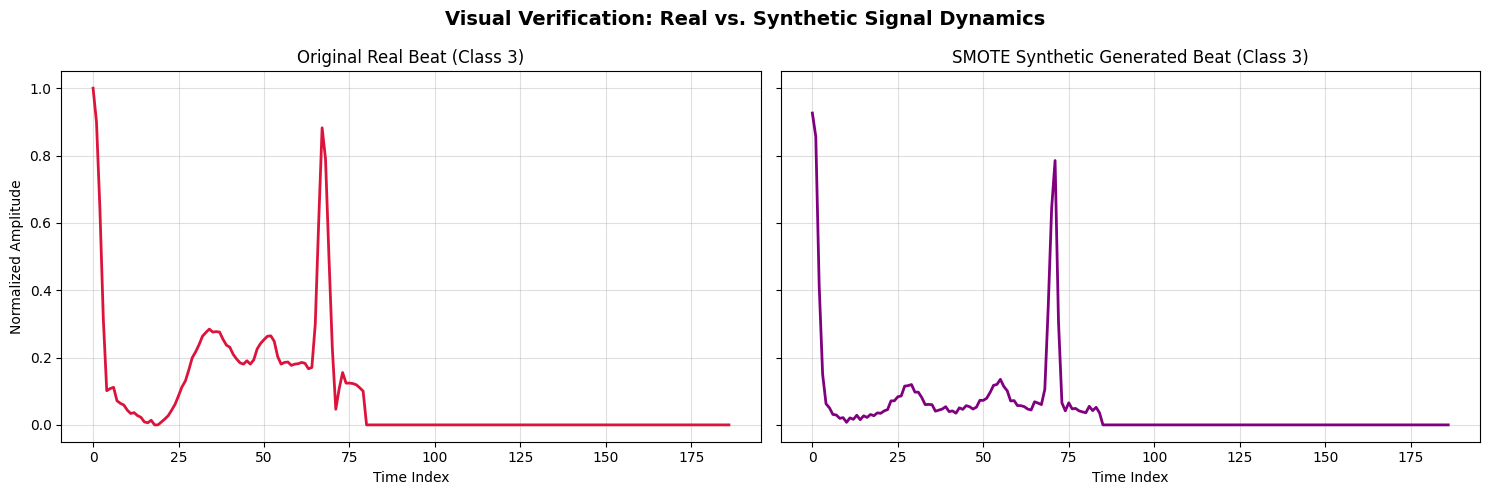

In [23]:
# 1. Choose a rare target class to verify (e.g., Class 3: Fusion Beat)
target_class = 3

# 2. Find a REAL sample from before SMOTE was applied
real_indices = np.where(y_under == target_class)[0]
real_sample = X_under.iloc[real_indices[0]].values

# 3. Find a SYNTHETIC sample from after SMOTE was applied
# Synthetic rows are added to the end of the dataset, so we grab one from the very back
all_indices = np.where(y_balanced == target_class)[0]
synthetic_sample = X_balanced.iloc[all_indices[-1]].values

# 4. Plot them side-by-side to verify the quality
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

# Plot Real Signal
ax1.plot(real_sample, color='crimson', linewidth=2)
ax1.set_title(f"Original Real Beat (Class {target_class})")
ax1.set_xlabel("Time Index")
ax1.set_ylabel("Normalized Amplitude")
ax1.grid(True, alpha=0.4)

# Plot SMOTE Generated Signal
ax2.plot(synthetic_sample, color='purple', linewidth=2)
ax2.set_title(f"SMOTE Synthetic Generated Beat (Class {target_class})")
ax2.set_xlabel("Time Index")
ax2.grid(True, alpha=0.4)

plt.suptitle(f"Visual Verification: Real vs. Synthetic Signal Dynamics", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

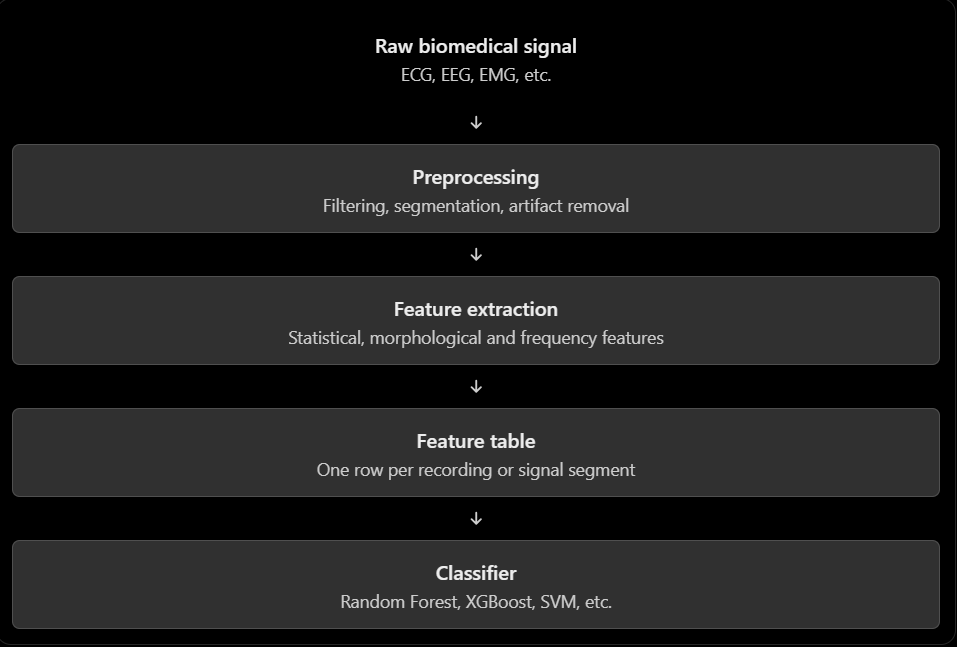

In [24]:
# ==========================================
# STEP B: LOAD THE TEST DATA (KEEP IT RAW)
# ==========================================
print("\nProcessing Testing Data...")
test_df = pd.read_csv('/kaggle/input/datasets/shayanfazeli/heartbeat/mitbih_test.csv')
X_test = test_df.iloc[:, :-1]
y_test = test_df.iloc[:, -1]

print(f"Original Test Distribution (Imbalanced): {Counter(y_test)}")
print("\nData preparation complete! You have separate, clean sets ready for modeling.")


Processing Testing Data...
Original Test Distribution (Imbalanced): Counter({0.0: 18117, 4.0: 1608, 2.0: 1448, 1.0: 556, 3.0: 162})

Data preparation complete! You have separate, clean sets ready for modeling.
